# IMPORT

In [46]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from tqdm import tqdm


# CONFIG

In [47]:
CLASS_NAMES = {
    1: "Fagus sylvatica",
    2: "Juglans regia",
    3: "Castanea sativa",
    4: "Quercus cerris",
    5: "Alnus glutinosa",
    6: "Fraxinus ornus",
    7: "Picea abies",
    8: "Pinus sylvestris",
    9: "Ailanthus altissima",
    10: "Robinia pseudoacacia",
    11: "Cupressus sempervirens",
    12: "Platanus orientalis"
}

# EDA

In [48]:
source = "../Wood Dataset"

# Train folder
train_folder = source + "/Train"

train_df = pd.DataFrame(columns=["image_path", "label"])

for folder in Path(train_folder).iterdir():
    for image_path in Path(folder).iterdir():
        train_df = pd.concat(
            [
                train_df,
                pd.DataFrame(
                    {
                        "image_path": [str(image_path)],
                        "label": [folder.name],
                    }
                ),
            ],
            ignore_index=True,
        )

display(train_df.head())

# Test folder
test_folder = source + "/Test"

test_df = pd.DataFrame(columns=["image_path", "label"])

for image_path in Path(test_folder).iterdir():
    path = Path(image_path).stem
    label = path.split("_")[1]

    test_df = pd.concat(
        [
            test_df,
            pd.DataFrame(
                {
                    "image_path": [str(image_path)],
                    "label": [label],
                }
            ),
        ],
        ignore_index=True,
    )

display(test_df.head())

,image_path,label
0,..\Wood Dataset\Train\1\100_1.jpg,1
1,..\Wood Dataset\Train\1\101_1.jpg,1
2,..\Wood Dataset\Train\1\102_1.jpg,1
3,..\Wood Dataset\Train\1\103_1.jpg,1
4,..\Wood Dataset\Train\1\104_1.jpg,1


,image_path,label
0,..\Wood Dataset\Test\1000_1.jpg,1
1,..\Wood Dataset\Test\1001_1.jpg,1
2,..\Wood Dataset\Test\1002_1.jpg,1
3,..\Wood Dataset\Test\1003_1.jpg,1
4,..\Wood Dataset\Test\1004_1.jpg,1


                               image_path label
count                                5708  5708
unique                               5708    12
top     ..\Wood Dataset\Train\1\100_1.jpg     3
freq                                    1  1024
label
3     1024
1      936
11     552
12     504
5      464
10     440
6      432
4      400
7      308
8      224
9      224
2      200
Name: count, dtype: int64


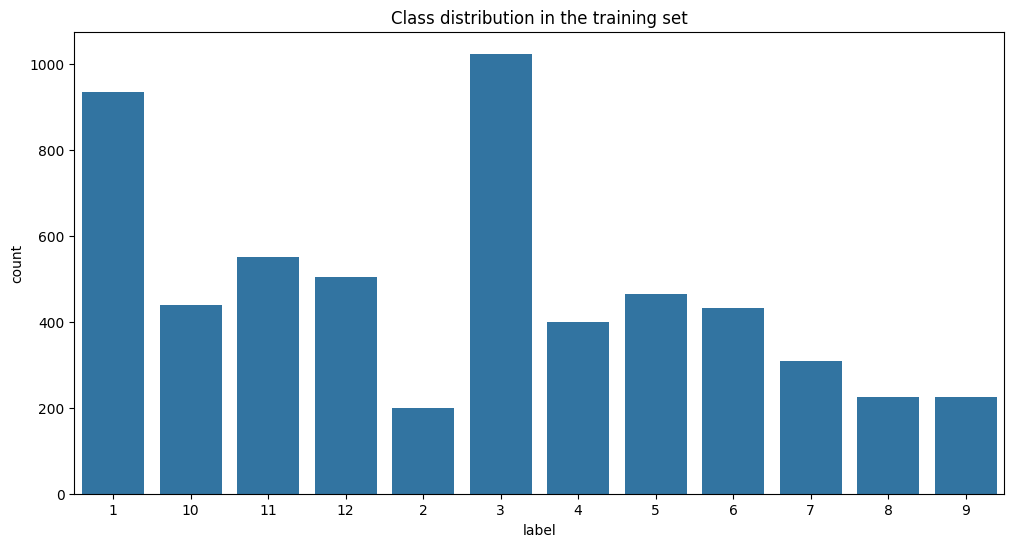

In [69]:
# How many images are there in the training set?
# How many images are there for each class in the training set?

def summary(df: pd.DataFrame):
    print(df.describe())
    print(df["label"].value_counts())

    plt.figure(figsize=(12, 6))
    sns.countplot(x="label", data=df)
    plt.title("Class distribution in the training set")
    plt.show()

summary(train_df)

In [74]:
# Size of the images in the training set


def get_image_properties(image_path):
    image = Image.open(image_path)
    return image.size, image.format, image.mode


def summary_sizes(df: pd.DataFrame):
    size_df = pd.DataFrame(columns=["image_path", "width", "height", "format", "mode"])

    for image_path in tqdm(df["image_path"]):
        image_size, image_format, image_mode = get_image_properties(image_path)
        size_df = pd.concat(
            [
                size_df,
                pd.DataFrame(
                    {
                        "image_path": [image_path],
                        "width": [image_size[0]],
                        "height": [image_size[1]],
                        "format": [image_format],
                        "mode": [image_mode],
                    }
                ),
            ],
            ignore_index=True,
        )
    return size_df


display(summary_sizes(train_df).head())

100%|██████████| 5708/5708 [00:04<00:00, 1238.39it/s]


,image_path,width,height,format,mode
0,..\Wood Dataset\Train\1\100_1.jpg,200,200,JPEG,RGB
1,..\Wood Dataset\Train\1\101_1.jpg,200,200,JPEG,RGB
2,..\Wood Dataset\Train\1\102_1.jpg,200,200,JPEG,RGB
3,..\Wood Dataset\Train\1\103_1.jpg,200,200,JPEG,RGB
4,..\Wood Dataset\Train\1\104_1.jpg,200,200,JPEG,RGB


                             image_path label
count                              2836  2836
unique                             2836    12
top     ..\Wood Dataset\Test\1000_1.jpg     3
freq                                  1   508
label
3     508
1     468
11    276
12    252
5     232
10    220
6     216
4     200
7     152
8     108
9     108
2      96
Name: count, dtype: int64


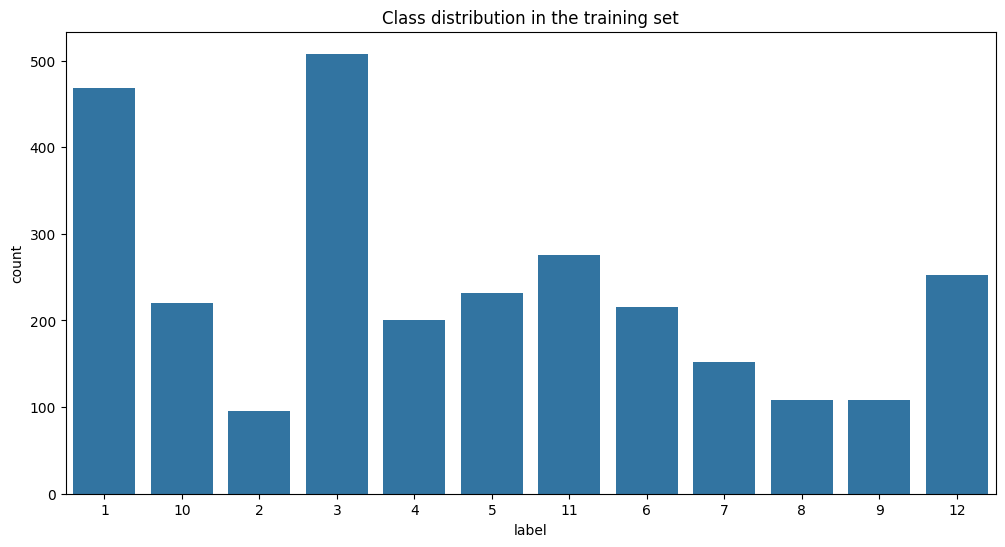

In [70]:
# How many images are there in the test set?
# How many images are there for each class in the test set?

summary(test_df)

In [75]:
# Image size in the test set

display(summary_sizes(test_df).head())

100%|██████████| 2836/2836 [00:02<00:00, 1072.24it/s]


,image_path,width,height,format,mode
0,..\Wood Dataset\Test\1000_1.jpg,200,200,JPEG,RGB
1,..\Wood Dataset\Test\1001_1.jpg,200,200,JPEG,RGB
2,..\Wood Dataset\Test\1002_1.jpg,200,200,JPEG,RGB
3,..\Wood Dataset\Test\1003_1.jpg,200,200,JPEG,RGB
4,..\Wood Dataset\Test\1004_1.jpg,200,200,JPEG,RGB
